# Mediation and sliding scale analysis of edge scores

This script calculates edge group scores. Then, runs mediation analysis for each edge group (M&G, A&G, M&A). Lastly, a sliding scale analysis is conducted to explore how edge scores change with increasing adversity.

Example data is provided in order to run the code. All original data is avaliable on the NBDC Data Hub (https://www.nbdc-datahub.org/).

Written by: Alexa Mousley (alexa.mousley@mrc-cbu.cam.ac.uk)
*October 2026*

In [ ]:
### Import packages ###

from A_config import  *       # Import custom paths
from A_functions import *     # Import custom function
import os                     # For combining paths
import numpy as np            # Basic requirements 
import pandas as pd           # Basic requirements

In [ ]:
### Load data ###

# Associated data
associated_data = pd.read_csv(os.path.join(data_dir,"associated_data_example.csv"))

# Networks
all_connectomes =  np.load(os.path.join(data_dir, "connectomes.npz"))['connectomes']
# Pull only networks for those with matching associated data
connectomes = all_connectomes[:,:,associated_data['imaging_index'].values]
nnodes, _, nsub = connectomes.shape # Define number of nodes and number of participants

# Matrices of edges that are stable for each PLS
adversity_edge_matrix = np.load(os.path.join(data_dir, 'adversity_edge_matrix_example.npy'))
mental_health_edge_matrix = np.load(os.path.join(data_dir, 'mental_health_edge_matrix_example.npy'))
genetics_LV1_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV1_edge_matrix_example.npy'))
genetics_LV2_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV2_edge_matrix_example.npy'))

# Set  up covariates for mediation
covs_continuous = StandardScaler().fit_transform(associated_data[['age', 'cognitive_score', 'dmri_meanmotion']].values.astype(float))
covs_categorical = associated_data[['sex', 'site', 'mrif_score', 'manufacturer_code', 'softwareversion_code']]
covariates = np.column_stack([covs_continuous, covs_categorical])
covariates = pd.DataFrame(covariates, columns=['age', 'cognitive_score','dmri_meanmotion', 'sex', 'site', 'mrif_score', 'manufacturer_code', 'softwareversion_code'])


In [4]:
### Calculate overlap and scores ###

overlap_masks, aligned_overlap_masks, overlap_percentages = extract_masks(
    adversity_edge_matrix, mental_health_edge_matrix, genetics_LV1_edge_matrix,
    names=['Adversity', 'Mental Health', 'Genetics'],flip=['Genetics'],)

edge_group_scores, edge_group_details = get_edge_group_scores(connectomes, aligned_overlap_masks)

Adversity (5,140 edges) & Mental Health (5,704 edges):
    1,349 overlapping edges, 1,077 shared edges grouped into: 372 Risk-aligned, 705 Health-aligned 

Adversity (5,140 edges) & Genetics (4,479 edges):
    1,146 overlapping edges, 777 shared edges grouped into: 332 Risk-aligned, 445 Health-aligned 

Mental Health (5,704 edges) & Genetics (4,479 edges):
    1,261 overlapping edges, 801 shared edges grouped into: 345 Risk-aligned, 456 Health-aligned 



Total effect (c, Adversity -> Mental Health) = 0.2921

M&A:
    a (Adversity -> M&A score)     = 0.1515
    b (M&A score -> Mental Health) = 0.0958
    c' (direct, Adversity -> Mental Health) = 0.2776
    indirect (a*b) = 0.0145 [95% CI 0.0105, 0.0189], p = 0.0010, FDR p = 0.0015 *

M&G:
    a (Adversity -> M&G score)     = 0.0612
    b (M&G score -> Mental Health) = 0.1231
    c' (direct, Adversity -> Mental Health) = 0.2846
    indirect (a*b) = 0.0075 [95% CI 0.0047, 0.0107], p = 0.0010, FDR p = 0.0015 *

A&G:
    a (Adversity -> A&G score)     = 0.1493
    b (A&G score -> Mental Health) = 0.0002
    c' (direct, Adversity -> Mental Health) = 0.2921
    indirect (a*b) = 0.0000 [95% CI -0.0041, 0.0041], p = 0.9900, FDR p = 0.9900


PermissionError: [Errno 13] Permission denied: '/imaging/astle/am11/ABCD/current_analysis/to_publish/github_repo/wired_resilience/example_data/mediation_barplot.pdf'

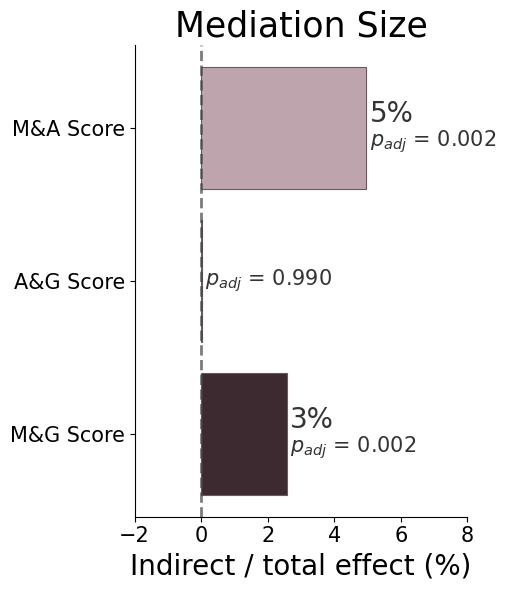

In [5]:
### Run and plot mediation analysis and create Figure 4a ###

mediation_results = run_edge_group_mediation(edge_group_scores, associated_data, covariates)

plot_mediation(mediation_results, save_path=save_dir)

M&A: r = +0.431, p = 7.45e-06, 65/100 windows significant after FDR
M&G: r = +0.553, p = 2.37e-09, 67/100 windows significant after FDR
A&G: r = -0.219, p = 2.83e-02, 0/100 windows significant after FDR


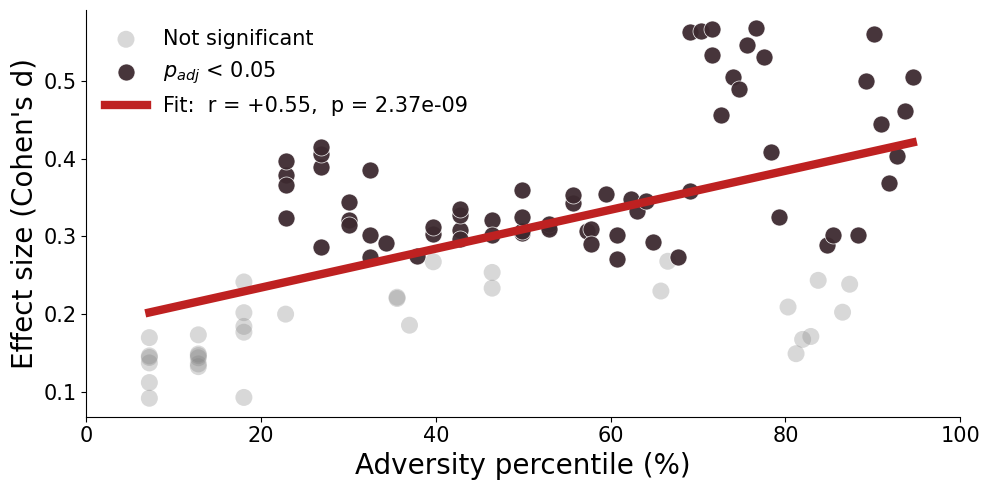

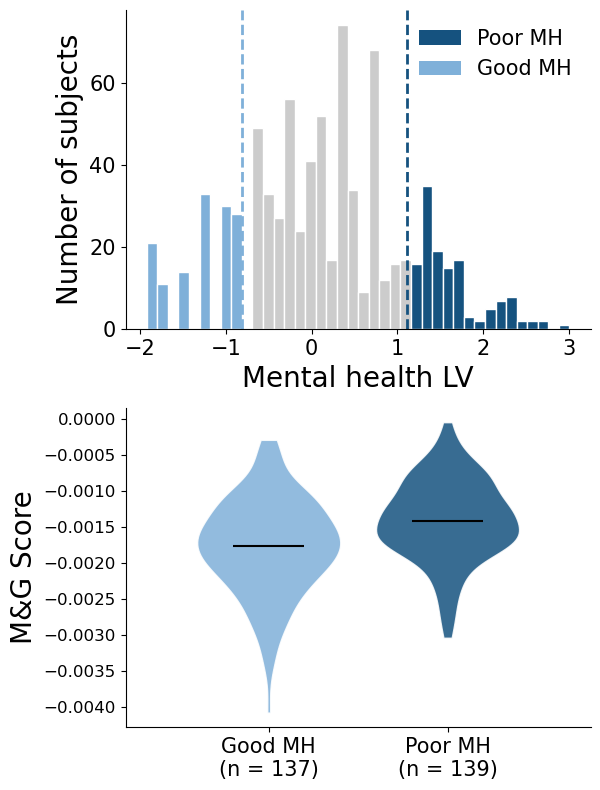

In [6]:
### Run sliding window analysis and create Figure 4b,c ###

run_sliding_window_analysis(edge_group_scores, associated_data,save_path=save_dir,
                            example_group='Mental Health & Genetics',example_pct=70)